In [36]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.patches as mpatches
from sklearn.model_selection import train_test_split

In [37]:
star = pd.read_csv("data/star.csv")

In [38]:
star.rename(
    columns={
        'Temperature (K)': 'Temperature', 
        'Luminosity(L/Lo)': 'Luminosity',
        'Radius(R/Ro)': 'Radius',
        'Absolute magnitude(Mv)': 'AbsoluteMagnitude',
        'Star type': 'StarType',
        'Star color': 'StarColour',
        'Spectral Class': 'SpectralClass'
    }, inplace=True
)

display(star)

,Temperature,Luminosity,Radius,AbsoluteMagnitude,StarType,StarColour,SpectralClass
0,3068,0.002400,0.1700,16.12,0,Red,M
1,3042,0.000500,0.1542,16.60,0,Red,M
2,2600,0.000300,0.1020,18.70,0,Red,M
3,2800,0.000200,0.1600,16.65,0,Red,M
4,1939,0.000138,0.1030,20.06,0,Red,M
...,...,...,...,...,...,...,...
235,38940,374830.000000,1356.0000,-9.93,5,Blue,O
236,30839,834042.000000,1194.0000,-10.63,5,Blue,O
237,8829,537493.000000,1423.0000,-10.73,5,White,A
238,9235,404940.000000,1112.0000,-11.23,5,White,A


In [39]:
for col in ['StarType', 'StarColour']:
    star[col] = star[col].astype('category')

spectral_order = ["O", "B", "A", "F", "G", "K", "M"]

star["SpectralClass"] = star["SpectralClass"].astype(
    pd.CategoricalDtype(categories=spectral_order, ordered=True)
)


In [40]:
star.groupby('StarType')['StarType'].count()

C:\Users\malin\AppData\Local\Temp\ipykernel_35624\3120671719.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  star.groupby('StarType')['StarType'].count()


StarType
0    40
1    40
2    40
3    40
4    40
5    40
Name: StarType, dtype: int64

In [41]:
star.groupby('StarColour')['StarColour'].count()

C:\Users\malin\AppData\Local\Temp\ipykernel_35624\1455695801.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  star.groupby('StarColour')['StarColour'].count()


StarColour
Blue                   55
Blue                    1
Blue White             10
Blue white              3
Blue white              1
Blue-White              1
Blue-white             26
Orange                  2
Orange-Red              1
Pale yellow orange      1
Red                   112
White                   7
White-Yellow            1
Whitish                 2
Yellowish               1
Yellowish White         3
white                   3
yellow-white            8
yellowish               2
Name: StarColour, dtype: int64

In [42]:
star.groupby('SpectralClass')['SpectralClass'].count()

C:\Users\malin\AppData\Local\Temp\ipykernel_35624\3845492809.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  star.groupby('SpectralClass')['SpectralClass'].count()


SpectralClass
O     40
B     46
A     19
F     17
G      1
K      6
M    111
Name: SpectralClass, dtype: int64

In [43]:
colour_dict = {
    'Red': ['Red'],
    'Blue-white': ['Blue-white', 'Blue White', 'Blue white', 'Blue white', 'Blue-White'], 
    'White': ['white', 'Whitish'],
    'Yellow-white': ['Yellowish White', 'yellow-white', 'White-Yellow'],
    'Yellow-orange': ['Pale yellow orange'],
    'Blue': ['Blue', 'Blue '],
    'Orange': ['Orange'],
    'Yellow': ['Yellowish', 'yellowish'],
    'Orange-red': ['Orange-red']
}

colour_map = {v: k for k, vv in colour_dict.items() for v in vv}

star['StarColour'] = (
    star['StarColour'].map(colour_map)
    .astype(pd.CategoricalDtype(categories=sorted(set(colour_map.values()))))
)

array([[<Axes: title={'center': 'Temperature'}>,
        <Axes: title={'center': 'Luminosity'}>],
       [<Axes: title={'center': 'Radius'}>,
        <Axes: title={'center': 'AbsoluteMagnitude'}>]], dtype=object)

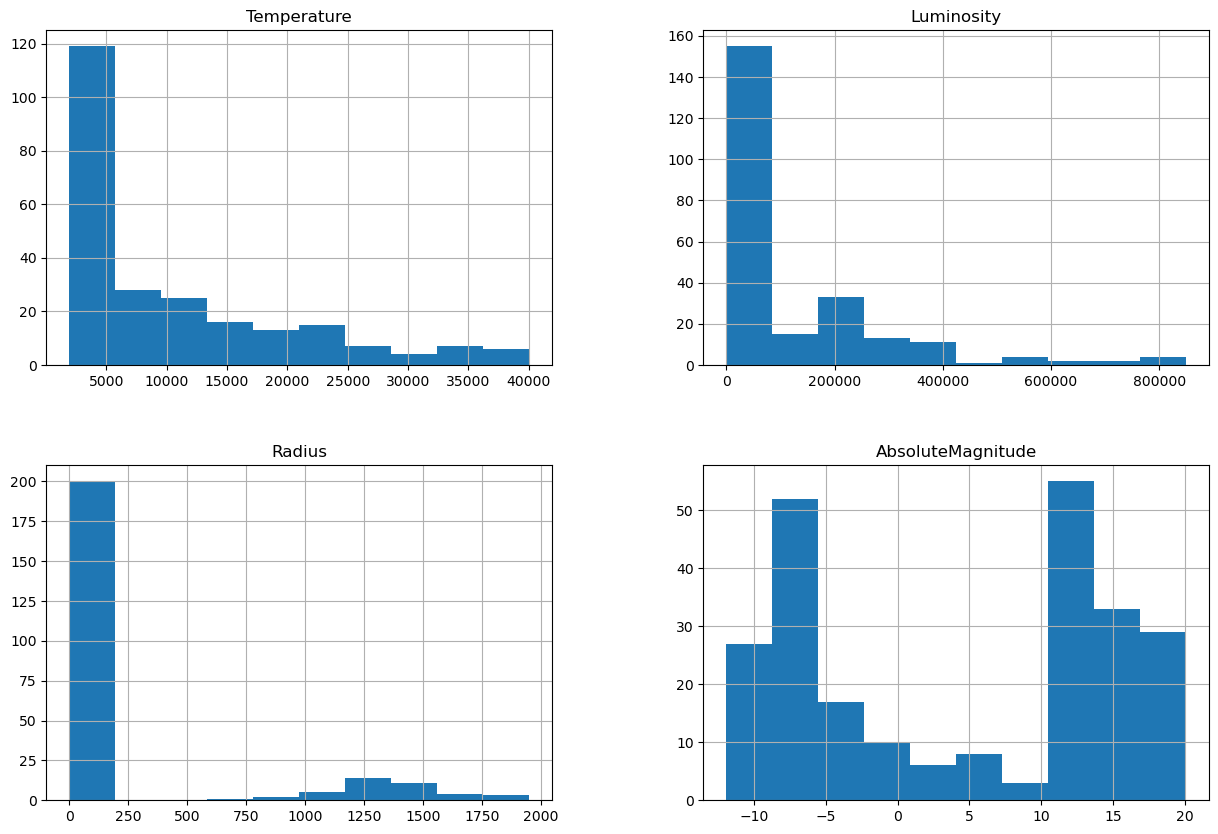

In [44]:
star.hist(figsize = (15,10))

<Axes: xlabel='StarType', ylabel='Temperature'>

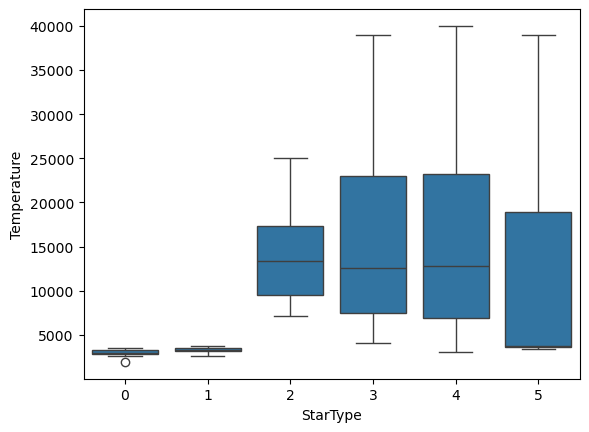

In [45]:
sns.boxplot(data=star, x='StarType', y='Temperature')

<Axes: xlabel='StarType', ylabel='Luminosity'>

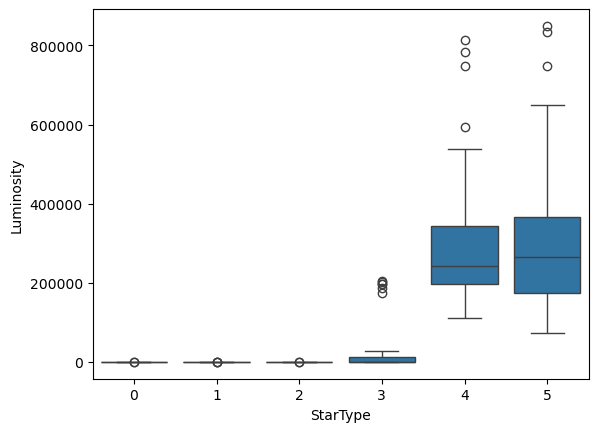

In [46]:
sns.boxplot(data=star, x='StarType', y='Luminosity')

<Axes: xlabel='StarType', ylabel='Radius'>

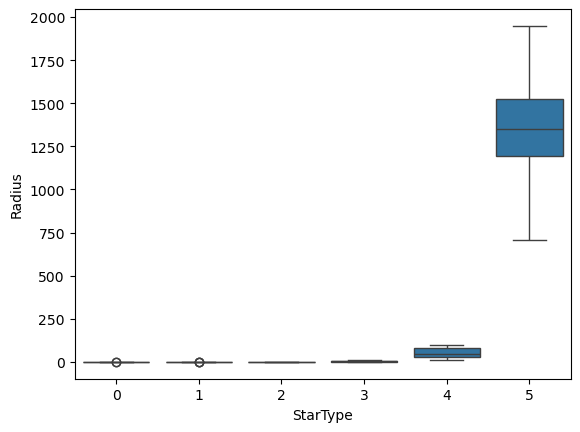

In [47]:
sns.boxplot(data=star, x='StarType', y='Radius')

<Axes: xlabel='StarType', ylabel='AbsoluteMagnitude'>

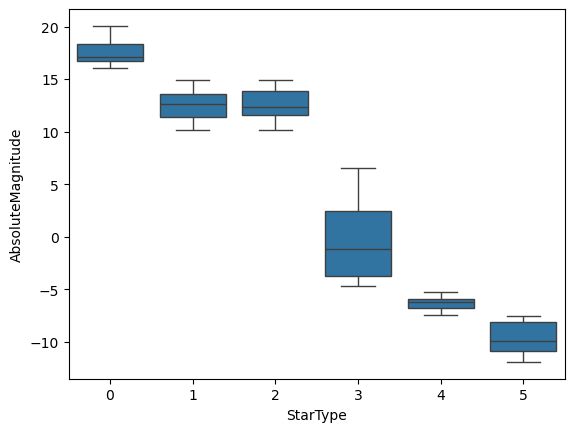

In [48]:
sns.boxplot(data=star, x='StarType', y='AbsoluteMagnitude')

In [49]:
agg_spectral = star.groupby(['StarType', 'SpectralClass'])['StarType'].count().unstack().fillna(0)
agg_spectral

C:\Users\malin\AppData\Local\Temp\ipykernel_35624\3526468421.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  agg_spectral = star.groupby(['StarType', 'SpectralClass'])['StarType'].count().unstack().fillna(0)


SpectralClass,O,B,A,F,G,K,M
StarType,,,,,,,
0,0,0,0,0,0,0,40
1,0,0,0,0,0,0,40
2,0,24,7,9,0,0,0
3,5,13,10,8,0,4,0
4,29,2,0,0,0,0,9
5,6,7,2,0,1,2,22


<Axes: xlabel='StarType', ylabel='Proportion'>

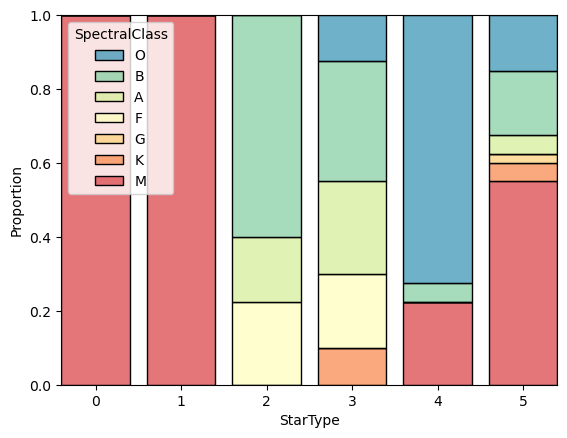

In [50]:
colour_spectral = sns.color_palette("Spectral_r", n_colors=7)

sns.histplot(
    data=star,
    x="StarType", 
    hue="SpectralClass",
    palette= colour_spectral,
    multiple="fill", 
    stat="proportion",
    discrete=True, 
    shrink=.8
)

<Axes: xlabel='StarType', ylabel='Proportion'>

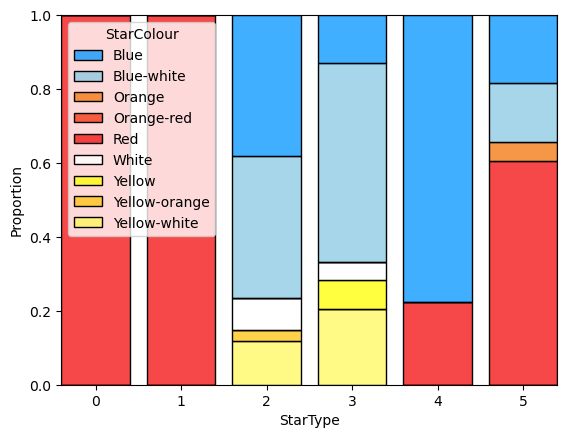

In [51]:
colour = ['#0095FF', '#8AC8E3', '#F4740B', '#F4320B', '#F40B0B', 'white', 'yellow', '#FFC30D', '#FFF75C']

sns.histplot(
    data=star,
    x="StarType", 
    hue="StarColour",
    palette=colour,
    multiple="fill", 
    stat="proportion",
    discrete=True, 
    shrink=.8
)

<Axes: xlabel='StarType', ylabel='Proportion'>

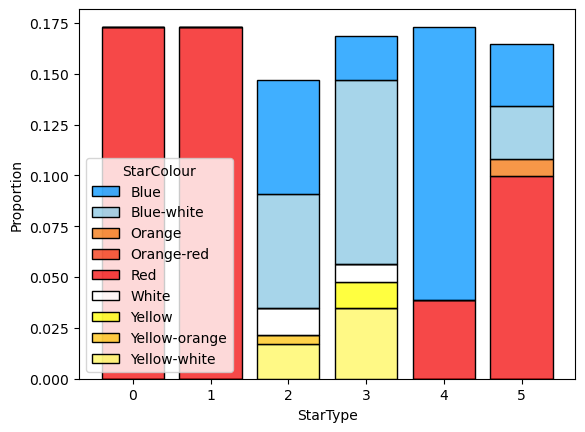

In [52]:
colour = ['#0095FF', '#8AC8E3', '#F4740B', '#F4320B', '#F40B0B', 'white', 'yellow', '#FFC30D', '#FFF75C']

sns.histplot(
    data=star,
    x="StarType", 
    hue="StarColour",
    palette=colour,
    multiple="stack", 
    stat="proportion",
    discrete=True, 
    shrink=.8
)

In [53]:
star.groupby('StarColour').count()

C:\Users\malin\AppData\Local\Temp\ipykernel_35624\1371605997.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  star.groupby('StarColour').count()


,Temperature,Luminosity,Radius,AbsoluteMagnitude,StarType,SpectralClass
StarColour,,,,,,
Blue,56,56,56,56,56,56
Blue-white,40,40,40,40,40,40
Orange,2,2,2,2,2,2
Orange-red,0,0,0,0,0,0
Red,112,112,112,112,112,112
White,5,5,5,5,5,5
Yellow,3,3,3,3,3,3
Yellow-orange,1,1,1,1,1,1
Yellow-white,12,12,12,12,12,12


In [54]:
star.dtypes

Temperature             int64
Luminosity            float64
Radius                float64
AbsoluteMagnitude     float64
StarType             category
StarColour           category
SpectralClass        category
dtype: object

In [55]:
y = star['StarType']
X = star.copy()
del X['StarType']

In [56]:
# Train/test split
data_train, data_test, target_train, target_test = train_test_split(
    X, y, random_state=42,test_size=0.25
)


In [57]:
#DummyClassifier
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import train_test_split

Dummy = DummyClassifier(strategy="most_frequent")
Dummy.fit(data_train, target_train)

accuracy = Dummy.score(data_test, target_test)

print(f"Accuracy of DummyClassifier: {accuracy:.3f}")

Accuracy of DummyClassifier: 0.150


In [58]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import make_column_selector as selector
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
categorical_preprocessor = OneHotEncoder(handle_unknown="ignore")
numerical_preprocessor = StandardScaler()

numerical_columns_selector = selector(dtype_exclude=["object", "string", "category"])
categorical_columns_selector = selector(dtype_include=["object", "string", "category"])
numerical_columns = numerical_columns_selector(X)
categorical_columns = categorical_columns_selector(X)

from sklearn.compose import make_column_transformer
preprocessor = make_column_transformer((categorical_preprocessor, categorical_columns), (numerical_preprocessor, numerical_columns))

Logistic_reg = make_pipeline(preprocessor, LogisticRegression(max_iter=500))
Logistic_reg.fit(data_train, target_train)
#predicted_target = model.predict(data_test)

accuracy = Logistic_reg.score(data_test, target_test)
print(f"Accuracy of logistic regression: {accuracy:.3f}")

Accuracy of logistic regression: 1.000


In [ ]:
#Test 1
print(X.columns)
print(y.name)

print(y.name in X.columns)


#Test 2
print(target_train.value_counts())
print(target_test.value_counts())

print(target_test.value_counts(normalize=True))


#Test 3
predicted_target = Logistic_reg.predict(data_test)

comparison = pd.DataFrame({
    "Actual": target_test,
    "Predicted": predicted_target
})

print(comparison)

#Test 4
from sklearn.metrics import confusion_matrix, classification_report

print(confusion_matrix(target_test, predicted_target))
print(classification_report(target_test, predicted_target))

#Test 5
print("Number of observations:", len(X))
print("Number of features:", X.shape[1])
print("Target distribution:\n", y.value_counts())
print("Target included in X:", y.name in X.columns)

Index(['Temperature', 'Luminosity', 'Radius', 'AbsoluteMagnitude',
       'StarColour', 'SpectralClass'],
      dtype='object')
StarType
False


In [64]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scores = cross_val_score(
    Logistic_reg,
    X,
    y,
    cv=cv,
    scoring="accuracy"
)

print("Cross-validation scores:", scores)
print("Mean accuracy:", scores.mean())
print("Standard deviation:", scores.std())

Cross-validation scores: [1.         1.         0.95833333 1.         1.        ]
Mean accuracy: 0.9916666666666668
Standard deviation: 0.016666666666666653


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder
from sklearn.compose import make_column_selector as selector
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.pipeline import make_pipeline

# Preprocessing
categorical_preprocessor = OrdinalEncoder(handle_unknown="use_encoded_value",unknown_value=-1,encoded_missing_value=-2)

numerical_columns_selector = selector(dtype_exclude=["object", "string", "category"])
categorical_columns_selector = selector(dtype_include=["object", "string", "category"])

numerical_columns = numerical_columns_selector(X)
categorical_columns = categorical_columns_selector(X)

preprocessor = make_column_transformer((categorical_preprocessor, categorical_columns),remainder="passthrough")

# Model
Histgrad = make_pipeline(preprocessor,HistGradientBoostingClassifier())
Histgrad.fit(data_train, target_train)

# Predictions and accuracy
predicted_target = Histgrad.predict(data_test)

accuracy = Histgrad.score(data_test, target_test)

print(f"Accuracy of HistGradientBoostingClassifier: {accuracy:.3f}")

Accuracy of HistGradientBoostingClassifier: 1.000


In [67]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scores = cross_val_score(
    Histgrad,
    X,
    y,
    cv=cv,
    scoring="accuracy"
)

print("Cross-validation scores:", scores)
print("Mean accuracy:", scores.mean())
print("Standard deviation:", scores.std())

Cross-validation scores: [1. 1. 1. 1. 1.]
Mean accuracy: 1.0
Standard deviation: 0.0
